MODULO 3 CAPITOLO 6 VIDEO 2 "REGRESSIONE RIDGE IN PYTHON "

In [3]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import fetch_california_housing
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import Ridge, RidgeCV, LinearRegression


In [4]:
data = fetch_california_housing(as_frame = True)
X = data.data
y = data.target


display (X)





,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25
...,...,...,...,...,...,...,...,...
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32


In [5]:
display(y)

0        4.526
1        3.585
2        3.521
3        3.413
4        3.422
         ...  
20635    0.781
20636    0.771
20637    0.923
20638    0.847
20639    0.894
Name: MedHouseVal, Length: 20640, dtype: float64

In [6]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [7]:
lin_reg = LinearRegression()
lin_reg.fit(X_scaled, y)
y_pred_lin = lin_reg.predict(X_scaled)

mse_lin = mean_squared_error(y, y_pred_lin)
r2_lin = r2_score(y, y_pred_lin)

print(f"MSE (Linear):\t{mse_lin:.4f}\nR2 (Linear):\t{r2_lin:.4f}")




MSE (Linear):	0.5243
R2 (Linear):	0.6062


In [8]:
r2_ridge = []
mse_ridge = []
alphas = np.logspace(-3, 3 , 100)

for a in alphas: 
    ridge = Ridge(alpha=a)
    ridge.fit(X_scaled, y)
    y_pred = ridge.predict(X_scaled)
    mse_ridge.append(mean_squared_error(y, y_pred))
    r2_ridge.append(r2_score(y, y_pred))

results = pd.DataFrame({"alpha": alphas, "MSE": mse_ridge, "R2": r2_ridge})
display(results)


,alpha,MSE,R2
0,0.001000,0.524321,0.606233
1,0.001150,0.524321,0.606233
2,0.001322,0.524321,0.606233
3,0.001520,0.524321,0.606233
4,0.001748,0.524321,0.606233
...,...,...,...
95,572.236766,0.534411,0.598655
96,657.933225,0.536670,0.596958
97,756.463328,0.539325,0.594965
98,869.749003,0.542413,0.592645


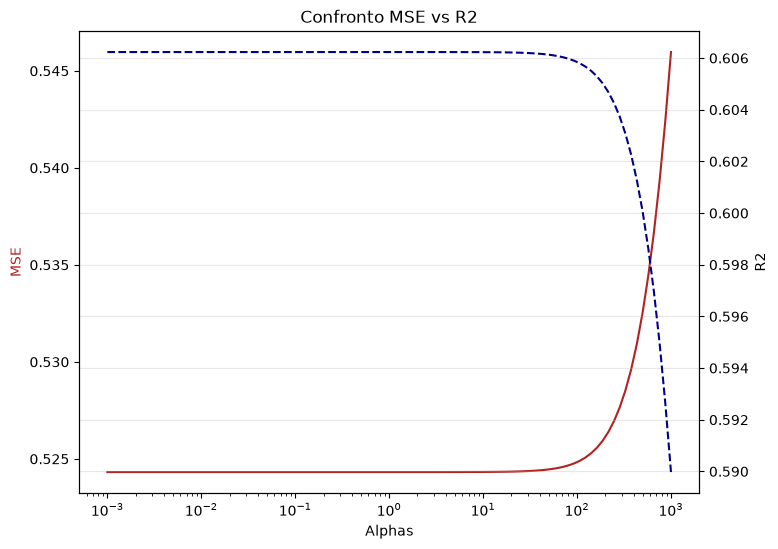

In [9]:
fig,ax1 = plt.subplots(figsize=(8,6))

ax1.plot(alphas, mse_ridge, "-", color = "firebrick")
ax1.set_xscale("log")
ax1.set_xlabel("Alphas")
ax1.set_ylabel("MSE", color = "firebrick")

ax2 = ax1.twinx()
ax2.plot(alphas, r2_ridge, "--", color = "darkblue")
ax2.set_ylabel("R2")

plt.title("Confronto MSE vs R2")
plt.grid(alpha = 0.3)
plt.show()


In [12]:
alphas_cv = alphas
ridge_cv = RidgeCV(alphas = alphas, store_cv_results = True)
ridge_cv.fit(X_scaled, y)

print(f"Alpha RidgeCV:\t{ridge_cv.alpha_:.4f}")

y_pred_cv = ridge_cv.predict(X_scaled)
mse_cv = mean_squared_error(y,y_pred_cv)
r2_cv = r2_score(y, y_pred_cv)

print(f"MSE:\t{mse_cv:.4f}\nR2:\t{r2_cv:.4f}")


Alpha RidgeCV:	30.5386
MSE:	0.5244
R2:	0.6062


In [15]:
best_index_man = np.argmin(mse_ridge)
best_alpha_man = alphas[best_index_man]
best_mse_man = mse_ridge[best_index_man]
best_r2_man = r2_ridge[best_index_man]

print(f"Alpha ridge:\t{best_alpha_man:.4f}\nMSE:\t{best_mse_man:.4f}\nR2:\t{best_r2_man:.4f}")

Alpha ridge:	0.0010
MSE:	0.5243
R2:	0.6062
